# Linear Algebra Intuition

Course source:
`../../../phases/01-math-foundations/01-linear-algebra-intuition/docs/en.md`

Web Page: https://aiengineeringfromscratch.com/lesson?path=phases%2F01-math-foundations%2F01-linear-algebra-intuition

Goal: rebuild enough linear algebra intuition to understand vectors,
matrices, matrix-vector multiplication, and why these matter in neural
networks.

Background: I have university-level maths experience but am rusty.
I am comfortable with TypeScript and learning Python.

## Vectors

I am working through the course lesson at:

`../../../phases/01-math-foundations/01-linear-algebra-intuition/docs/en.md`

Please read the lesson and teach it interactively. I am rusty on
university maths, so rebuild intuition without assuming I remember the
formal terminology.

Work in small sections:
1. Explain one idea at a time.
2. Use concrete numerical examples before notation where possible.
3. Ask me to predict or calculate something small before showing the
   answer.
4. Relate each idea to code and, when relevant, neural networks.
5. Do not move to the next lesson section until I confirm I understand
   the current one.

Start with the first concept in the course document.

##### 🤖Reply🤖<!-- SOLVEIT_SEPARATOR_7f3a9b2c -->

I’ll read the lesson file first so we can begin with its actual first concept.
- ⏳ `py(code="from fastcore.tools import view_file\nvie…")` ⏳


````json {.tool}
{
  "id": "fc_0ad09c81ddb31e77016ac3412fd83887d1af35d0a3de249a36",
  "name": "py",
  "args": {
    "code": "from fastcore.tools import view_file\nview_file(r'''../../../phases/01-math-foundations/01-linear-algebra-intuition/docs/en.md''')"
  },
  "result": "1: # Linear Algebra Intuition\n2: \n3: > Every AI model is just matrix math wearing a fancy hat.\n4: \n5: **Type:** Learn\n6: **Languages:** Python, Julia\n7: **Prerequisites:** Phase 0\n8: **Time:** ~60 minutes\n9: \n10: ## Learning Objectives\n11: \n12: - Implement vector and matrix operations (addition, dot product, matrix multiply) from scratch in Python\n13: - Explain geometrically what the dot product, projection, and Gram-Schmidt process do\n14: - Determine linear independence, rank, and basis of a set of vectors using row reduction\n15: - Connect linear algebra concepts to their AI applications: embeddings, attention scores, and LoRA\n16: \n17: ## The Problem\n18: \n19: Open any ML paper. Within the first page, you'll see vectors, matrices, dot products, and transformations. Without linear algebra intuition, these are just symbols. With it, you can see what a neural network is actually doing -- moving points around in space.\n20: \n21: You don't need to be a mathematician. You need to see what these operations mean geometrically, then code them yourself.\n22: \n23: ## The Concept\n24: \n25: ### Vectors Are Points (and Directions)\n26: \n27: A vector is just a list of numbers. But those numbers mean something -- they're coordinates in space.\n28: \n29: **2D vector [3, 2]:**\n30: \n31: | x | y | Point |\n32: |---|---|-------|\n33: | 3 | 2 | The vector points from origin (0,0) to (3, 2) on the plane |\n34: \n35: The vector has magnitude sqrt(3^2 + 2^2) = sqrt(13) and points up and to the right.\n36: \n37: In AI, vectors represent everything:\n38: - A word → a vector of 768 numbers (its \"meaning\" in embedding space)\n39: - An image → a vector of millions of pixel values\n40: - A user → a vector of preferences\n41: \n42: ### Matrices Are Transformations\n43: \n44: A matrix transforms one vector into another. It can rotate, scale, stretch, or project.\n45: \n46: ```mermaid\n47: graph LR\n48:     subgraph Before\n49:         A[\"Point A\"]\n50:         B[\"Point B\"]\n51:     end\n52:     subgraph Matrix[\"Matrix Multiplication\"]\n53:         M[\"M (transformation)\"]\n54:     end\n55:     subgraph After\n56:         A2[\"Point A'\"]\n57:         B2[\"Point B'\"]\n58:     end\n59:     A --> M\n60:     B --> M\n61:     M --> A2\n62:     M --> B2\n63: ```\n64: \n65: In AI, matrices ARE the model:\n66: - Neural network weights → matrices that transform input into output\n67: - Attention scores → matrices that decide what to focus on\n68: - Embeddings → matrices that map words to vectors\n69: \n70: ### The Dot Product Measures Similarity\n71: \n72: The dot product of two vectors tells you how similar they are.\n73: \n74: ```\n75: a · b = a₁×b₁ + a₂×b₂ + ... + aₙ×bₙ\n76: \n77: Same direction:      a · b > 0  (similar)\n78: Perpendicular:       a · b = 0  (unrelated)\n79: Opposite direction:  a · b < 0  (dissimilar)\n80: ```\n81: \n82: This is literally how search engines, recommendation systems, and RAG work -- find vectors with high dot products.\n83: \n84: ### Linear Independence\n85: \n86: Vectors are linearly independent if no vector in the set can be written as a combination of the others. If v1, v2, v3 are independent, they span a 3D space. If one is a combination of the others, they only span a plane.\n87: \n88: Why it matters for AI: your feature matrix should have linearly independent columns. If two features are perfectly correlated (linearly dependent), the model cannot distinguish their effects. This causes multicollinearity in regression -- the weight matrix becomes unstable, and small input changes produce wild output swings.\n89: \n90: **Concrete example:**\n91: \n92: ```\n93: v1 = [1, 0, 0]\n94: v2 = [0, 1, 0]\n95: v3 = [2, 1, 0]   # v3 = 2*v1 + v2\n96: ```\n97: \n98: v1 and v2 are independent -- neither is a scalar multiple or combination of the other. But v3 = 2*v1 + v2, so {v1, v2, v3} is a dependent set. These three vectors all lie in the xy-plane. No matter how you combine them, you cannot reach [0, 0, 1]. You have three vectors but only two dimensions of freedom.\n99: \n100: In a dataset: if feature_3 = 2*feature_1 + feature_2, adding feature_3 gives the model zero new information. Worse, it makes the normal equations singular -- there is no unique solution for the weights.\n101: \n102: ### Basis and Rank\n103: \n104: A basis is a minimal set of linearly independent vectors that span the entire space. The number of basis vectors is the dimension of the space.\n105: \n106: The standard basis for 3D space is {[1,0,0], [0,1,0], [0,0,1]}. But any three independent vectors in 3D form a valid basis. The choice of basis is a choice of coordinate system.\n107: \n108: Rank of a matrix = number of linearly independent columns = number of linearly independent rows. If rank < min(rows, cols), the matrix is rank-deficient. This means:\n109: - The system has infinitely many solutions (or none)\n110: - Information is lost in the transformation\n111: - The matrix cannot be inverted\n112: \n113: | Situation | Rank | What it means for ML |\n114: |-----------|------|---------------------|\n115: | Full rank (rank = min(m, n)) | Maximum possible | Unique least-squares solution exists. Model is well-conditioned. |\n116: | Rank deficient (rank < min(m, n)) | Below maximum | Features are redundant. Infinitely many weight solutions. Regularization needed. |\n117: | Rank 1 | 1 | Every column is a scaled copy of one vector. All data lies on a line. |\n118: | Near rank-deficient (small singular values) | Numerically low | Matrix is ill-conditioned. Tiny input noise causes large output changes. Use SVD truncation or ridge regression. |\n119: \n120: ### Projection\n121: \n122: Projecting vector **a** onto vector **b** gives the component of **a** in the direction of **b**:\n123: \n124: ```\n125: proj_b(a) = (a dot b / b dot b) * b\n126: ```\n127: \n128: The residual (a - proj_b(a)) is perpendicular to b. This orthogonal decomposition is the foundation of least-squares fitting.\n129: \n130: Projection is everywhere in ML:\n131: - Linear regression minimizes the distance from observations to the column space -- the solution IS a projection\n132: - PCA projects data onto the directions of maximum variance\n133: - Attention in transformers computes projections of queries onto keys\n134: \n135: ```mermaid\n136: graph LR\n137:     subgraph Projection[\"Projection of a onto b\"]\n138:         direction TB\n139:         O[\"Origin\"] --> |\"b (direction)\"| B[\"b\"]\n140:         O --> |\"a (original)\"| A[\"a\"]\n141:         O --> |\"proj_b(a)\"| P[\"projection\"]\n142:         A -.-> |\"residual (perpendicular)\"| P\n143:     end\n144: ```\n145: \n146: **Example:** a = [3, 4], b = [1, 0]\n147: \n148: proj_b(a) = (3*1 + 4*0) / (1*1 + 0*0) * [1, 0] = 3 * [1, 0] = [3, 0]\n149: \n150: The projection drops the y-component. This is dimensionality reduction in its simplest form -- throw away the directions you don't care about.\n151: \n152: ### Gram-Schmidt Process\n153: \n154: Converting any set of independent vectors into an orthonormal basis. Orthonormal means every vector has length 1 and every pair is perpendicular.\n155: \n156: The algorithm:\n157: 1. Take the first vector, normalize it\n158: 2. Take the second vector, subtract its projection onto the first, normalize\n159: 3. Take the third vector, subtract its projections onto all previous vectors, normalize\n160: 4. Repeat for remaining vectors\n161: \n162: ```\n163: Input:  v1, v2, v3, ... (linearly independent)\n164: \n165: u1 = v1 / |v1|\n166: \n167: w2 = v2 - (v2 dot u1) * u1\n168: u2 = w2 / |w2|\n169: \n170: w3 = v3 - (v3 dot u1) * u1 - (v3 dot u2) * u2\n171: u3 = w3 / |w3|\n172: \n173: Output: u1, u2, u3, ... (orthonormal basis)\n174: ```\n175: \n176: This is how QR decomposition works internally. Q is the orthonormal basis, R captures the projection coefficients. QR decomposition is used in:\n177: - Solving linear systems (more stable than Gaussian elimination)\n178: - Computing eigenvalues (QR algorithm)\n179: - Least-squares regression (the standard numerical method)\n180: \n181: ```figure\n182: eigen-directions\n183: ```\n184: \n185: ## Build It\n186: \n187: ### Step 1: Vectors from scratch (Python)\n188: \n189: ```python\n190: class Vector:\n191:     def __init__(self, components):\n192:         self.components = list(components)\n193:         self.dim = len(self.components)\n194: \n195:     def __add__(self, other):\n196:         return Vector([a + b for a, b in zip(self.components, other.components)])\n197: \n198:     def __sub__(self, other):\n199:         return Vector([a - b for a, b in zip(self.components, other.components)])\n200: \n201:     def dot(self, other):\n202:         return sum(a * b for a, b in zip(self.components, other.components))\n203: \n204:     def magnitude(self):\n205:         return sum(x**2 for x in self.components) ** 0.5\n206: \n207:     def normalize(self):\n208:         mag = self.magnitude()\n209:         return Vector([x / mag for x in self.components])\n210: \n211:     def cosine_similarity(self, other):\n212:         return self.dot(other) / (self.magnitude() * other.magnitude())\n213: \n214:     def __repr__(self):\n215:         return f\"Vector({self.components})\"\n216: \n217: \n218: a = Vector([1, 2, 3])\n219: b = Vector([4, 5, 6])\n220: \n221: print(f\"a + b = {a + b}\")\n222: print(f\"a · b = {a.dot(b)}\")\n223: print(f\"|a| = {a.magnitude():.4f}\")\n224: print(f\"cosine similarity = {a.cosine_similarity(b):.4f}\")\n225: ```\n226: \n227: ### Step 2: Matrices from scratch (Python)\n228: \n229: ```python\n230: class Matrix:\n231:     def __init__(self, rows):\n232:         self.rows = [list(row) for row in rows]\n233:         self.shape = (len(self.rows), len(self.rows[0]))\n234: \n235:     def __matmul__(self, other):\n236:         if isinstance(other, Vector):\n237:             return Vector([\n238:                 sum(self.rows[i][j] * other.components[j] for j in range(self.shape[1]))\n239:                 for i in range(self.shape[0])\n240:             ])\n241:         rows = []\n242:         for i in range(self.shape[0]):\n243:             row = []\n244:             for j in range(other.shape[1]):\n245:                 row.append(sum(\n246:                     self.rows[i][k] * other.rows[k][j]\n247:                     for k in range(self.shape[1])\n248:                 ))\n249:             rows.append(row)\n250:         return Matrix(rows)\n251: \n252:     def transpose(self):\n253:         return Matrix([\n254:             [self.rows[j][i] for j in range(self.shape[0])]\n255:             for i in range(self.shape[1])\n256:         ])\n257: \n258:     def __repr__(self):\n259:         return f\"Matrix({self.rows})\"\n260: \n261: \n262: rotation_90 = Matrix([[0, -1], [1, 0]])\n263: point = Vector([3, 1])\n264: \n265: rotated = rotation_90 @ point\n266: print(f\"Original: {point}\")\n267: print(f\"Rotated 90°: {rotated}\")\n268: ```\n269: \n270: ### Step 3: Why this matters for AI\n271: \n272: ```python\n273: import random\n274: \n275: random.seed(42)\n276: weights = Matrix([[random.gauss(0, 0.1) for _ in range(3)] for _ in range(2)])\n277: input_vector = Vector([1.0, 0.5, -0.3])\n278: \n279: output = weights @ input_vector\n280: print(f\"Input (3D): {input_vector}\")\n281: print(f\"Output (2D): {output}\")\n282: print(\"This is what a neural network layer does -- matrix multiplication.\")\n283: ```\n284: \n285: ### Step 4: Julia version\n286: \n287: ```julia\n288: a = [1.0, 2.0, 3.0]\n289: b = [4.0, 5.0, 6.0]\n290: \n291: println(\"a + b = \", a + b)\n292: println(\"a · b = \", a ⋅ b)       # Julia supports unicode operators\n293: println(\"|a| = \", √(a ⋅ a))\n294: println(\"cosine = \", (a ⋅ b) / (√(a ⋅ a) * √(b ⋅ b)))\n295: \n296: # Matrix-vector multiplication\n297: W = [0.1 -0.2 0.3; 0.4 0.5 -0.1]\n298: x = [1.0, 0.5, -0.3]\n299: println(\"Wx = \", W * x)\n300: println(\"This is a neural network layer.\")\n301: ```\n302: \n303: ### Step 5: Linear independence and projection from scratch (Python)\n304: \n305: ```python\n306: def is_linearly_independent(vectors):\n307:     n = len(vectors)\n308:     dim = len(vectors[0].components)\n309:     mat = Matrix([v.components[:] for v in vectors])\n310:     rows = [row[:] for row in mat.rows]\n311:     rank = 0\n312:     for col in range(dim):\n313:         pivot = None\n314:         for row in range(rank, len(rows)):\n315:             if abs(rows[row][col]) > 1e-10:\n316:                 pivot = row\n317:                 break\n318:         if pivot is None:\n319:             continue\n320:         rows[rank], rows[pivot] = rows[pivot], rows[rank]\n321:         scale = rows[rank][col]\n322:         rows[rank] = [x / scale for x in rows[rank]]\n323:         for row in range(len(rows)):\n324:             if row != rank and abs(rows[row][col]) > 1e-10:\n325:                 factor = rows[row][col]\n326:                 rows[row] = [rows[row][j] - factor * rows[rank][j] for j in range(dim)]\n327:         rank += 1\n328:     return rank == n\n329: \n330: \n331: def project(a, b):\n332:     scalar = a.dot(b) / b.dot(b)\n333:     return Vector([scalar * x for x in b.components])\n334: \n335: \n336: def gram_schmidt(vectors):\n337:     orthonormal = []\n338:     for v in vectors:\n339:         w = v\n340:         for u in orthonormal:\n341:             proj = project(w, u)\n342:             w = w - proj\n343:         if w.magnitude() < 1e-10:\n344:             continue\n345:         orthonormal.append(w.normalize())\n346:     return orthonormal\n347: \n348: \n349: v1 = Vector([1, 0, 0])\n350: v2 = Vector([1, 1, 0])\n351: v3 = Vector([1, 1, 1])\n352: basis = gram_schmidt([v1, v2, v3])\n353: for i, u in enumerate(basis):\n354:     print(f\"u{i+1} = {u}\")\n355:     print(f\"  |u{i+1}| = {u.magnitude():.6f}\")\n356: \n357: print(f\"u1 · u2 = {basis[0].dot(basis[1]):.6f}\")\n358: print(f\"u1 · u3 = {basis[0].dot(basis[2]):.6f}\")\n359: print(f\"u2 · u3 = {basis[1].dot(basis[2]):.6f}\")\n360: ```\n361: \n362: ## Use It\n363: \n364: Now the same thing with NumPy -- what you'll actually use in practice:\n365: \n366: ```python\n367: import numpy as np\n368: \n369: a = np.array([1, 2, 3], dtype=float)\n370: b = np.array([4, 5, 6], dtype=float)\n371: \n372: print(f\"a + b = {a + b}\")\n373: print(f\"a · b = {np.dot(a, b)}\")\n374: print(f\"|a| = {np.linalg.norm(a):.4f}\")\n375: print(f\"cosine = {np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b)):.4f}\")\n376: \n377: W = np.random.randn(2, 3) * 0.1\n378: x = np.array([1.0, 0.5, -0.3])\n379: print(f\"Wx = {W @ x}\")\n380: ```\n381: \n382: ### Rank, Projection, and QR with NumPy\n383: \n384: ```python\n385: import numpy as np\n386: \n387: A = np.array([[1, 2], [2, 4]])\n388: print(f\"Rank: {np.linalg.matrix_rank(A)}\")\n389: \n390: a = np.array([3, 4])\n391: b = np.array([1, 0])\n392: proj = (np.dot(a, b) / np.dot(b, b)) * b\n393: print(f\"Projection of {a} onto {b}: {proj}\")\n394: \n395: Q, R = np.linalg.qr(np.random.randn(3, 3))\n396: print(f\"Q is orthogonal: {np.allclose(Q @ Q.T, np.eye(3))}\")\n397: print(f\"R is upper triangular: {np.allclose(R, np.triu(R))}\")\n398: ```\n399: \n400: ### PyTorch -- Tensors Are Vectors with Autodiff\n401: \n402: ```python\n403: import torch\n404: \n405: x = torch.randn(3, requires_grad=True)\n406: y = torch.tensor([1.0, 0.0, 0.0])\n407: \n408: similarity = torch.dot(x, y)\n409: similarity.backward()\n410: \n411: print(f\"x = {x.data}\")\n412: print(f\"y = {y.data}\")\n413: print(f\"dot product = {similarity.item():.4f}\")\n414: print(f\"d(dot)/dx = {x.grad}\")\n415: ```\n416: \n417: The gradient of the dot product with respect to x is just y. PyTorch computed this automatically. Every operation in a neural network is built from operations like this -- matrix multiplies, dot products, projections -- and autodiff tracks gradients through all of them.\n418: \n419: You just built from scratch what NumPy does in one line. Now you know what's happening under the hood.\n420: \n421: ## Ship It\n422: \n423: This lesson produces:\n424: - `outputs/prompt-linear-algebra-tutor.md` -- a prompt for AI assistants to teach linear algebra through geometric intuition\n425: \n426: ## Connections\n427: \n428: Everything in this lesson connects to specific parts of modern AI:\n429: \n430: | Concept | Where it shows up |\n431: |---------|------------------|\n432: | Dot product | Attention scores in transformers, cosine similarity in RAG |\n433: | Matrix multiply | Every neural network layer, every linear transformation |\n434: | Linear independence | Feature selection, avoiding multicollinearity |\n435: | Rank | Determining if a system is solvable, LoRA (low-rank adaptation) |\n436: | Projection | Linear regression (projecting onto column space), PCA |\n437: | Gram-Schmidt / QR | Numerical solvers, eigenvalue computation |\n438: | Orthonormal basis | Stable numerical computation, whitening transforms |\n439: \n440: LoRA deserves special mention. It fine-tunes large language models by decomposing weight updates into low-rank matrices. Instead of updating a 4096x4096 weight matrix (16M parameters), LoRA updates two matrices of size 4096x16 and 16x4096 (131K parameters). The rank-16 constraint means LoRA assumes the weight update lives in a 16-dimensional subspace of the full 4096-dimensional space. That is linear algebra doing real work.\n441: \n442: ## Exercises\n443: \n444: 1. Implement `Vector.angle_between(other)` that returns the angle in degrees between two vectors\n445: 2. Create a 2D scaling matrix that doubles the x-coordinate and triples the y-coordinate, then apply it to the vector [1, 1]\n446: 3. Given 5 random word-like vectors (dimension 50), find the two most similar using cosine similarity\n447: 4. Verify that the Gram-Schmidt output is truly orthonormal: check that every pair has dot product 0 and every vector has magnitude 1\n448: 5. Create a 3x3 matrix with rank 2. Verify using the `rank()` method. Then explain what geometric object the columns span.\n449: 6. Project the vector [1, 2, 3] onto [1, 1, 1]. What does the result represent geometrically?\n450: \n451: ## Key Terms\n452: \n453: | Term | What people say | What it actually means |\n454: |------|----------------|----------------------|\n455: | Vector | \"An arrow\" | A list of numbers representing a point or direction in n-dimensional space |\n456: | Matrix | \"A table of numbers\" | A transformation that maps vectors from one space to another |\n457: | Dot product | \"Multiply and sum\" | A measure of how aligned two vectors are -- the core of similarity search |\n458: | Embedding | \"Some AI magic\" | A vector that represents the meaning of something (word, image, user) |\n459: | Linear independence | \"They don't overlap\" | No vector in the set can be written as a combination of the others |\n460: | Rank | \"How many dimensions\" | The number of linearly independent columns (or rows) in a matrix |\n461: | Projection | \"The shadow\" | The component of one vector in the direction of another |\n462: | Basis | \"The coordinate axes\" | A minimal set of independent vectors that span the space |\n463: | Orthonormal | \"Perpendicular unit vectors\" | Vectors that are mutually perpendicular and each have length 1 |"
}
````





We’ll start with **vectors**: a vector is simply an ordered list of numbers that describes a position or a movement.

For example:

```text
[3, 2]
```

means:

- move **3 units right**
- move **2 units up**

Starting at the origin, `(0, 0)`, you arrive at the point `(3, 2)`.

So you can picture `[3, 2]` in two equivalent ways:

- a **point** located at `(3, 2)`
- an **arrow** from `(0, 0)` to `(3, 2)`

The order matters: `[3, 2]` is different from `[2, 3]`.

In Python, we would usually represent it as a list or array:

```python
v = [3, 2]
```

In AI, the same idea scales up. Instead of two coordinates, a word might be represented by a vector with 768 numbers. Each number is a coordinate in a very high-dimensional space; together, they encode useful patterns about the word.

Small check: if you start at `(0, 0)`, where do you end up after following the vector `[-2, 5]`?

You would end up at x = -2 and y = 5. Do we happen to have access to a graphing library like matplotlib? I feel like it some diagrams of the vectors would also helpt

##### 🤖Reply🤖<!-- SOLVEIT_SEPARATOR_7f3a9b2c -->

Correct: the endpoint is **(-2, 5)** — 2 left and 5 up.

Yes, `matplotlib` is available, and diagrams are an excellent idea here. Run this to draw both vectors from the origin:

```python
import matplotlib.pyplot as plt

vectors = [[3, 2], [-2, 5]]
colors = ["tab:blue", "tab:orange"]

for (x, y), color in zip(vectors, colors):
    plt.quiver(0, 0, x, y, angles="xy", scale_units="xy", scale=1, color=color)

plt.xlim(-4, 5)
plt.ylim(-1, 6)
plt.axhline(0, color="black")
plt.axvline(0, color="black")
plt.grid()
plt.gca().set_aspect("equal")
plt.show()
```

`plt.quiver(0, 0, x, y, ...)` means: draw an arrow starting at `(0, 0)` and ending at `(x, y)`.

Before running it: where do you predict the blue arrow `[3, 2]` and orange arrow `[-2, 5]` will lie relative to each other?

I think that the blue arrow will be in the top right quandrant pointing further right and up and the orange arrow will be in the top left quadrant pointing further left and up.

Is that kind of what you were asking for as an answer?

##### 🤖Reply🤖<!-- SOLVEIT_SEPARATOR_7f3a9b2c -->

Exactly — that is what I was asking for.

- **Blue** `[3, 2]`: right 3, up 2 → top-right quadrant.
- **Orange** `[-2, 5]`: left 2, up 5 → top-left quadrant.

One small vocabulary point: each arrow is a **vector**, and its endpoint is a **point**. For vectors starting at the origin, those two pictures line up neatly.

Run the graph when ready. Notice that the orange vector is taller, while the blue one reaches farther right.

In [ ]:
import matplotlib.pyplot as plt

In [ ]:
vectors = [[3, 2], [-2, 5]]

colors = ["tab:blue", "tab:orange"]

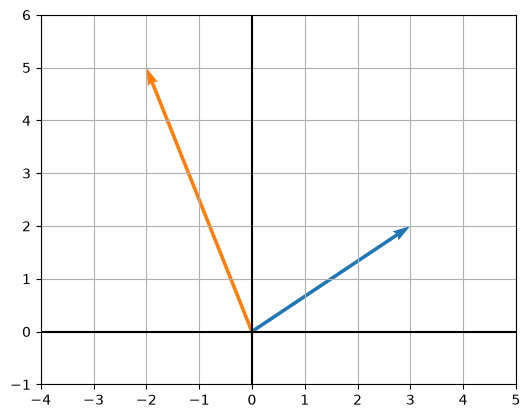

In [ ]:
for (x, y), color in zip(vectors, colors):
    plt.quiver(0, 0, x, y, angles="xy", scale_units="xy", scale=1, color=color)

plt.xlim(-4, 5)
plt.ylim(-1, 6)

# Create the x and y axes
plt.axhline(0, color="black")
plt.axvline(0, color="black")

plt.grid()

plt.gca().set_aspect("equal")

plt.show()

Yes the orange vector seems to be longer (greater magnitude?) than the blue vector.

##### 🤖Reply🤖<!-- SOLVEIT_SEPARATOR_7f3a9b2c -->

Yes — **magnitude** is the right word. It means the vector’s length.

Using Pythagoras:

- Blue `[3, 2]` has magnitude  
  \[
  \sqrt{3^2 + 2^2} = \sqrt{13} \approx 3.6
  \]

- Orange `[-2, 5]` has magnitude  
  \[
  \sqrt{(-2)^2 + 5^2} = \sqrt{29} \approx 5.4
  \]

The negative `x` coordinate says “left”; when calculating a length, squaring makes it positive.

Try this one: what do you predict the magnitude of `[0, 4]` is, before calculating it?

I think 4 because only 1 of the dimensions of the vector has a non-zero value

##### 🤖Reply🤖<!-- SOLVEIT_SEPARATOR_7f3a9b2c -->

Exactly right:  

\[
\sqrt{0^2 + 4^2}=\sqrt{16}=4
\]

Geometrically, `[0, 4]` is a vertical arrow from `(0, 0)` to `(0, 4)`, so its length is plainly 4.

A useful shortcut follows:

- `[a, 0]` has magnitude \(|a|\)
- `[0, b]` has magnitude \(|b|\)

The absolute value matters because `[0, -4]` points down, but is still length 4.

Next, vectors can be **added**: combining two movements into one.

### Addition

In [ ]:
def two_d_plot(vectors, colors):
    for (x, y), color in zip(vectors, colors):
        plt.quiver(0, 0, x, y, angles="xy", scale_units="xy", scale=1, color=color)

    plt.xlim(-4, 5)
    plt.ylim(-4, 8)

    # Create the x and y axes
    plt.axhline(0, color="black")
    plt.axvline(0, color="black")

    plt.grid()

    plt.gca().set_aspect("equal")

    plt.show()

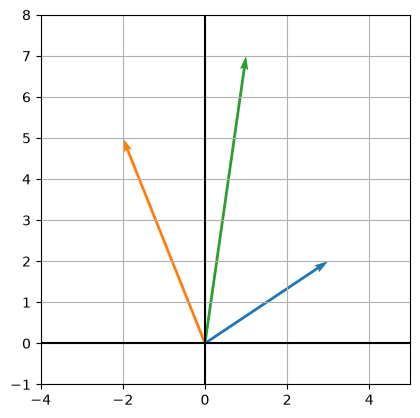

In [ ]:
v_a = [3, 2]
v_b = [-2, 5]

v_c = [3 + -2, 2 + 5]

vectors = [v_a, v_b, v_c]
colors = ["tab:blue", "tab:orange", "tab:green"]

two_d_plot(vectors, colors)

In [ ]:
vec = vectors[:-1]

col = colors[:-1]
vec, col

([[3, 2], [-2, 5]], ['tab:blue', 'tab:orange'])

In [ ]:
v_c

[1, 7]

x = 3, y = 2, color = tab:blue


start_x = 0, start_y = 0


end_x = 3, end_y = 2


x = -2, y = 5, color = tab:orange


start_x = 3, start_y = 2


end_x = 1, end_y = 7


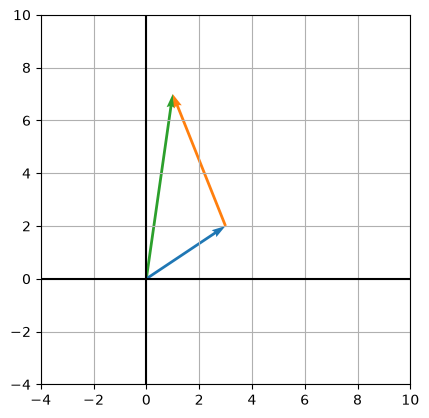

In [ ]:
start_x = 0

start_y = 0
plt.quiver(0, 0, v_c[0], v_c[1], angles="xy", scale_units="xy", scale=1, color="tab:green")

for (x, y), color in zip(vec, colors[:-1]):
    
    print(f"x = {x}, y = {y}, color = {color}")
    print(f"start_x = {start_x}, start_y = {start_y}")
    end_x = start_x + x
    end_y = start_y + y

    print(f"end_x = {end_x}, end_y = {end_y}")
    
    plt.quiver(start_x, start_y, x, y, angles="xy", scale_units="xy", scale=1, color=color)

    start_x = end_x
    start_y = end_y

plt.xlim(-4, 10)
plt.ylim(-4, 10)

# Create the x and y axes
plt.axhline(0, color="black")
plt.axvline(0, color="black")

plt.grid()

plt.gca().set_aspect("equal")

plt.show()

Why does my 2nd arrow not end at the x=1, y=7 co-ordinate in the plot?

##### 🤖Reply🤖<!-- SOLVEIT_SEPARATOR_7f3a9b2c -->

`plt.quiver` takes:

```python
plt.quiver(start_x, start_y, change_in_x, change_in_y, ...)
```

The third and fourth arguments are the arrow’s **movement**, not its final coordinates.

For the orange vector, you correctly calculated its endpoint as `(1, 7)`, but then gave `quiver`:

```python
plt.quiver(3, 2, 1, 7, ...)
```

Matplotlib reads that as:

- start at `(3, 2)`
- move `1` right and `7` up

so it ends at `(4, 9)`.

Use the vector components `x, y` for the arrow movement:

```python
plt.quiver(start_x, start_y, x, y,
           angles="xy", scale_units="xy", scale=1, color=color)
```

Your endpoint calculation is still useful for updating the next arrow’s starting position:

```python
end_x = start_x + x
end_y = start_y + y
```

So the key distinction is:

- `(end_x, end_y)` describes a **point**
- `(x, y)` describes a **vector displacement**

Thank you, that makes sense.

I wanted to show graphically how adding vectors look. It seems that adding is chaining them from tail to head?

##### 🤖Reply🤖<!-- SOLVEIT_SEPARATOR_7f3a9b2c -->

Yes. **Tail-to-head chaining** is exactly the graphical meaning of vector addition.

For your vectors:

1. Draw `v_a = [3, 2]` from `(0, 0)` to `(3, 2)`.
2. Start `v_b = [-2, 5]` at the head of `v_a`, so it moves from `(3, 2)` to `(1, 7)`.
3. The sum is the single green vector from the original tail `(0, 0)` to the final head `(1, 7)`:

\[
[3,2] + [-2,5] = [1,7]
\]

So the chained path and the one green “resultant” arrow represent the same overall movement.

Your loop now captures this idea correctly:

```python
plt.quiver(start_x, start_y, x, y, ...)
```

It draws each vector as a movement from the endpoint of the previous one.

A useful prediction: if you drew the orange vector first and then the blue one, where would the final endpoint be?

I think the resultant vector would end up being the same.

##### 🤖Reply🤖<!-- SOLVEIT_SEPARATOR_7f3a9b2c -->

Correct. The final endpoint is still `(1, 7)`.

\[
[3,2] + [-2,5] = [-2,5] + [3,2] = [1,7]
\]

That property is called **commutativity**: changing the order does not change the sum.

Graphically, the two possible tail-to-head paths make a parallelogram, and the resultant is the same diagonal from the origin.

Ok so that is adding vectors. I assume that subtracting vectors is the same as adding the negative value of each of the co-ordinates?

##### 🤖Reply🤖<!-- SOLVEIT_SEPARATOR_7f3a9b2c -->

Exactly.

To subtract a vector, add its **opposite**: negate each coordinate.

\[
[3,2] - [-2,5]
=
[3,2] + [2,-5]
=
[5,-3]
\]

The opposite of `[-2, 5]` is `[2, -5]`:

- instead of 2 left, go 2 right;
- instead of 5 up, go 5 down.

Graphically, reversing a vector flips its arrow by 180°.

Small check: what is the opposite of `[4, -1]`?

The opposite would be [-(4), -(-1)] = [-4, 1] 

##### 🤖Reply🤖<!-- SOLVEIT_SEPARATOR_7f3a9b2c -->

Exactly: the opposite of `[4, -1]` is `[-4, 1]`.

Adding a vector to its opposite gives the zero vector:

\[
[4,-1] + [-4,1] = [0,0]
\]

That is the vector version of a number plus its negative equalling zero. The zero vector means “no movement.”

### Dot Product

What about the Dot Product, what does it tell us about two vectors and how does that work again?


##### 🤖Reply🤖<!-- SOLVEIT_SEPARATOR_7f3a9b2c -->

The **dot product** takes two vectors and produces a single number, called a **scalar**.

For 2D vectors, multiply matching coordinates, then add:

\[
[a,b] \cdot [c,d] = a\times c + b\times d
\]

For example:

\[
[3,2]\cdot[-2,5]
= 3(-2) + 2(5)
= -6 + 10
= 4
\]

So the dot product is `4`, not another arrow/vector.

Why is that useful? It tells us about how much the vectors point in the **same general direction**:

- positive dot product: somewhat aligned
- zero: perpendicular (at right angles)
- negative: generally point in opposite directions

There is one important caveat: the dot product also gets larger when vectors are longer. Later, we’ll remove that length effect with **cosine similarity**, which AI often uses for comparing embeddings.

Try this calculation:

\[
[2,1]\cdot[-1,3]
\]

What number do you get?

In [ ]:
a = [3, 2]
b = [-2, 5]

# a . b = 3 * -2  + 2 * 5
# a . b = -6 + 10 = 4


In [ ]:
def dot_prod(a, b):
    # Takes two vectors, a & b of the same dimension and returns the dot product scalar

    # Positive dot product: vectors somewhat aligned
    # Negative dot negative: vectors generally point in opposite directions
    # Zero dot product: vectors are perpendicular (at right angles)

    return sum(a_i * b_i for (a_i, b_i) in zip(a, b))

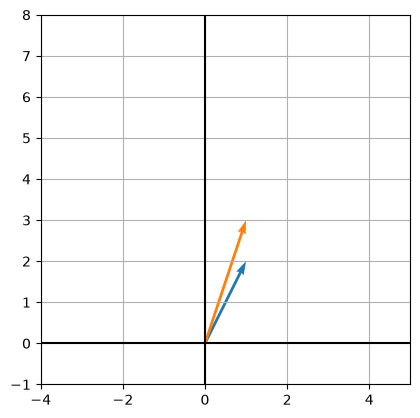

a_dot_b =  7


In [ ]:
# Positive Dot Product = somewhat aligned

a =  [1, 2]
b =  [1, 3]

two_d_plot([a, b], ["tab:blue", "tab:orange"])

# Previous attempt: a_dot_b = sum(a[i] * b[i] for i in range(0, len(a)))
# Can use zip to ensure that the vectors are the same dimension

# a_dot_b = sum(a_i * b_i for (a_i, b_i) in zip(a, b))

a_dot_b = dot_prod(a, b)


print(f"a_dot_b =  {a_dot_b}")

Why is the a_dot_b invalid syntax?

##### 🤖Reply🤖<!-- SOLVEIT_SEPARATOR_7f3a9b2c -->

The `for ... in ...` part is a **generator expression**. Python requires it either:

- inside a function call such as `sum(...)`, or
- wrapped in parentheses.

For a dot product, you want to **sum** the coordinate-wise products:

```python
a_dot_b = sum(a[i] * b[i] for i in range(len(a)))
```

More idiomatically, avoid indexing with `zip`:

```python
a_dot_b = sum(x * y for x, y in zip(a, b))
```

For your vectors `[1, 2]` and `[1, 3]`, that computes:

\[
1 \times 1 + 2 \times 3 = 7
\]

If you merely wrote parentheses around your original expression, Python would create a generator — a lazy sequence of products — rather than the final dot-product number.

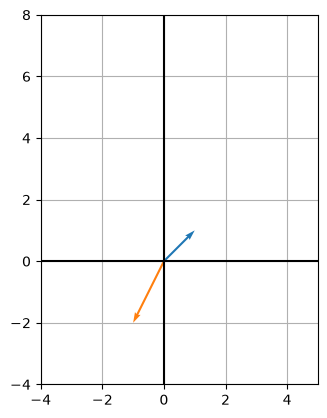

c_dot_d =  -3


In [ ]:
# Negative Dot Product = Generally point in opposite directions

c = [1, 1]
d = [-1, -2]

two_d_plot([c, d], ["tab:blue", "tab:orange"])

c_dot_d = dot_prod(c, d)

print(f"c_dot_d =  {c_dot_d}")


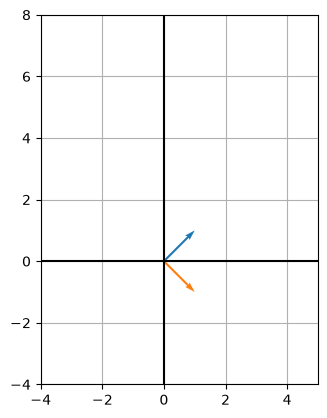

e_dot_f =  0


In [ ]:
# Zero (0) Dot Product = Vectors are perpendicular with each other

e = [1, 1]
f = [1, -1]

two_d_plot([e, f], ["tab:blue", "tab:orange"])

e_dot_f = dot_prod(e, f)

print(f"e_dot_f =  {e_dot_f}")


So we need the dimensions of the two vectors to be the same in order to calculate the dot product?

##### 🤖Reply🤖<!-- SOLVEIT_SEPARATOR_7f3a9b2c -->

Yes. A dot product pairs up matching coordinates, so both vectors must have the same number of components.

For example:

\[
[1,2,3]\cdot[4,5,6]
=1(4)+2(5)+3(6)
=32
\]

But `[1, 2] · [3, 4, 5]` is not defined: the first vector has no third coordinate to pair with `5`.

In code, it is worth checking this explicitly, since `zip(a, b)` silently stops at the shorter list:

```python
assert len(a) == len(b)
a_dot_b = sum(x * y for x, y in zip(a, b))
```

Geometrically, this is because the vectors need to live in the same space: both 2D, both 3D, or both 768-dimensional embeddings.

So if we have two vectors that have a 0 dot product, does that me we could theoretically use them as the axes? 

##### 🤖Reply🤖<!-- SOLVEIT_SEPARATOR_7f3a9b2c -->

Yes — provided neither vector is the zero vector.

Two **non-zero** vectors with dot product `0` are perpendicular. In 2D, that means they point in two distinct directions, so together they can serve as the axes of a new coordinate system.

Your example works:

\[
[1,1]\cdot[1,-1] = 1(1)+1(-1)=0
\]

So instead of the usual axes

\[
[1,0], \quad [0,1]
\]

you could use diagonal axes:

\[
[1,1], \quad [1,-1]
\]

They are perpendicular, but each has length \(\sqrt{2}\), not \(1\). If we scale each to length 1, they become an **orthonormal basis**—perpendicular axes with a standard unit length.

One exception: the zero vector has dot product \(0\) with every vector, but it cannot be an axis because it has no direction.

Can you see why `[1, 1]` and `[1, -1]` look like diagonals relative to the ordinary x- and y-axes?

### Linear Independence

Please tell me about vector linear independence 

##### 🤖Reply🤖<!-- SOLVEIT_SEPARATOR_7f3a9b2c -->

**Linear independence** asks:

> Does each vector contribute a genuinely new direction, or can one be constructed from the others?

Consider two 2D vectors:

\[
a=[1,0], \qquad b=[0,1]
\]

No amount of scaling \(a\) can produce \(b\): \(a\) only points horizontally, while \(b\) points vertically. They are **linearly independent**, and together they let us reach any point in 2D:

\[
[3,2]=3a+2b
\]

Now compare:

\[
a=[1,2], \qquad b=[2,4]
\]

Here,

\[
b=2a
\]

Thus \(b\) adds no new direction. The vectors are **linearly dependent**: both lie along the same line.

For **two non-zero 2D vectors**, the quick geometric test is:

- different directions → independent;
- parallel or anti-parallel → dependent.

This matters in AI datasets: if one feature is an exact combination of others, it provides no new information and can make model weights ambiguous.

Small check: are these vectors independent or dependent?

\[
a=[1,2],\qquad b=[3,1]
\]

Try deciding whether some number multiplied by \(a\) could produce \(b\).

In [ ]:
v1 = [1, 0, 0]
v2 = [0, 1, 0]
v3 = [2, 1, 0]   # v3 = 2*v1 + v2

In this case, V three is equal to two times V one plus V two.

Does that mean in order for a vector to be independent, it has to have a length on an axis that other vectors do not have?

e.g. if v3 was [2, 1, 1] that would be linearly independent from v1 and v2

##### 🤖Reply🤖<!-- SOLVEIT_SEPARATOR_7f3a9b2c -->

Yes—for **this particular pair** \(v_1\) and \(v_2\), your reasoning is correct.

\[
v_1=[1,0,0],\qquad v_2=[0,1,0]
\]

Every combination of them has the form

\[
a v_1+b v_2=[a,b,0]
\]

so they can reach anywhere in the \(xy\)-plane, but their \(z\)-coordinate is always zero.

Therefore,

\[
v_3=[2,1,1]
\]

cannot be constructed from \(v_1\) and \(v_2\), because its \(z\)-coordinate is \(1\). Thus the set

\[
\{v_1,v_2,v_3\}
\]

is linearly independent.

The broader rule is not that a vector must use an axis unused by the others. Rather:

> A new vector is independent of the existing vectors if it lies outside all the directions their combinations can already reach—their **span**.

Here, the unused \(z\)-axis provides an easy way to see that.

Small prediction: would \([7,-3,0]\) add a new independent direction to \(v_1\) and \(v_2\)?

In [ ]:
v4 = [7,-3,0] # v4 = 7 * v1 - 3 * v2 ?

Can we minus away vectors? In my head, the scaling kinda means like positive values. Um and because V two is in the positive let's say y axis direction, it isn't in the negative y axis direction, which is what V four is. Um so if we can't use sort of negative scales of minusing away vectors then I guess this would be linearly independent. 

##### 🤖Reply🤖<!-- SOLVEIT_SEPARATOR_7f3a9b2c -->

Yes, we **can use negative scaling**. In a linear combination, the scale factors may be positive, negative, zero, or fractional.

Multiplying by a negative number reverses a vector’s direction:

\[
-3v_2=-3[0,1,0]=[0,-3,0]
\]

Therefore,

\[
7v_1-3v_2
=7[1,0,0]-3[0,1,0]
=[7,-3,0]
=v_4
\]

So \(v_4\) is **linearly dependent** on \(v_1\) and \(v_2\). Although \(v_2\) points in the positive \(y\)-direction, negative multiples of it let us move in the negative \(y\)-direction too.

Together, \(v_1\) and \(v_2\) span the entire \(xy\)-plane—not merely its positive quadrant. A vector would need to leave that plane, such as `[7, -3, 1]`, to add a new independent direction.

Could you provide like a basic example of linear independence in an AI data set?

##### 🤖Reply🤖<!-- SOLVEIT_SEPARATOR_7f3a9b2c -->

Imagine a recommendation model trained on three users:

| User | Action films watched | Comedy films watched | Total films watched |
|---|---:|---:|---:|
| A | 1 | 0 | 1 |
| B | 0 | 1 | 1 |
| C | 1 | 1 | 2 |

Looking down the columns, our feature vectors are:

```python
action = [1, 0, 1]
comedy = [0, 1, 1]
total  = [1, 1, 2]
```

But:

\[
\text{total}=\text{action}+\text{comedy}
\]

Therefore, `total` contains **no new information**. If the model already knows the first two features, it can calculate the third exactly. These three feature columns are linearly dependent.

This can create ambiguity when training a model. For example, it could attribute an effect to `total`, or split the same effect between `action` and `comedy`; multiple weight combinations can produce identical predictions.

Now suppose we replace `total` with:

```python
subscriber = [0, 0, 1]
```

Can `subscriber` be constructed by scaling and adding `action` and `comedy`, or does it add an independent feature direction?

In [ ]:
action = [1, 0, 1]
comedy = [0, 1, 1]
subscriber = [0, 0, 1]

Subscriber is linearly independent of action and comedy because any non-zero scaling of those will add magnitude in the other axes which subscribe doesn't have.

##### 🤖Reply🤖<!-- SOLVEIT_SEPARATOR_7f3a9b2c -->

Exactly. A combination of `action` and `comedy` looks like:

\[
a[1,0,1]+b[0,1,1]=[a,b,a+b]
\]

To match `subscriber = [0,0,1]`:

- first coordinate forces \(a=0\)
- second coordinate forces \(b=0\)
- but then the third coordinate is \(a+b=0\), not \(1\)

So no choice of positive, negative, or fractional scaling factors works. `subscriber` adds genuinely new information, making these three feature vectors linearly independent.

Could you please give me a quick rundown of the math notation like \q other math notation that you show? sometimes I I think it's hard to to understand when it's not rendered.

##### 🤖Reply🤖<!-- SOLVEIT_SEPARATOR_7f3a9b2c -->

Certainly. The notation is written using **LaTeX**, a common way to format mathematics. If it fails to render, you may see commands beginning with `\`.

Here are the main symbols we have used:

| Rendered | Raw notation | Meaning |
|---|---|---|
| \(v_1\) | `v_1` | Vector \(v\), number 1; `_` creates a subscript |
| \(2v_1\) | `2v_1` | Scale \(v_1\) by 2 |
| \(v_1+v_2\) | `v_1 + v_2` | Add two vectors |
| \(a\cdot b\) | `a \cdot b` | Dot product |
| \(\sqrt{13}\) | `\sqrt{13}` | Square root of 13 |
| \(a\neq b\) | `a \neq b` | \(a\) is not equal to \(b\) |
| \(\{v_1,v_2\}\) | `\{v_1, v_2\}` | A set containing two vectors |
| \(\lVert v\rVert\) | `\lVert v \rVert` | Magnitude or length of \(v\) |
| \(v\in\mathbb{R}^3\) | `v \in \mathbb{R}^3` | \(v\) is a three-dimensional real vector |

For example:

\[
a[1,0,1]+b[0,1,1]=[a,b,a+b]
\]

means:

- scale `[1, 0, 1]` by some number \(a\);
- scale `[0, 1, 1]` by some number \(b\);
- add the results;
- the resulting vector is `[a, b, a+b]`.

The formatting markers themselves are:

- `\( ... \)` — inline mathematics
- `\[ ... \]` — mathematics on a separate line
- `\quad` — extra horizontal space
- `\qquad` — even more horizontal space

`\q` by itself is not standard LaTeX notation; it may have been the beginning of `\quad` or `\qquad`.

Is there a way for Solveit to render LaTeX? Or if not, is there like a Python package I could maybe import that would allow me to render LaTeX um as an output?

##### 🤖Reply🤖<!-- SOLVEIT_SEPARATOR_7f3a9b2c -->

- ⏳ `web_search(type="search", queries="['site:solveit.fast.ai LaTeX math render…", query="site:solveit.fast.ai LaTeX math renderin…")` ⏳


```json {.tool}
{
  "id": "ws_07649537f80c4e04006ad3f7415af487d1a3ac094e2ed9ddf1",
  "name": "web_search",
  "args": {
    "type": "search",
    "queries": [
      "site:solveit.fast.ai LaTeX math rendering Solveit markdown",
      "site:forums.fast.ai Solveit LaTeX MathJax",
      "site:fast.ai solveit markdown latex"
    ],
    "query": "site:solveit.fast.ai LaTeX math rendering Solveit markdown"
  },
  "result": "Server tool call executed.",
  "server": true
}
```


- ⏳ `web_search(type="open_page", url="https://www.fast.ai/posts/2025-11-07-sol…")` ⏳


```json {.tool}
{
  "id": "ws_07649537f80c4e04006ad3f7475b2c87d1818fa97abdafec16",
  "name": "web_search",
  "args": {
    "type": "open_page",
    "url": "https://www.fast.ai/posts/2025-11-07-solveit-features.html"
  },
  "result": "Server tool call executed.",
  "server": true
}
```


- ⏳ `web_search(type="open_page", url="https://www.fast.ai/posts/2025-11-07-sol…")` ⏳


```json {.tool}
{
  "id": "ws_07649537f80c4e04006ad3f748efb087d1b9bd9d1fac1b7b39",
  "name": "web_search",
  "args": {
    "type": "open_page",
    "url": "https://www.fast.ai/posts/2025-11-07-solveit-features.html"
  },
  "result": "Server tool call executed.",
  "server": true
}
```

Yes—Solveit can render LaTeX directly using **KaTeX**, so you do not need a Python package.

On Solveit’s dialog-list/dashboard page:

1. Find the **Secrets/environment variables** section.
2. Add a variable named `USE_KATEX`.
3. Set its value to:
   - `1` for safe delimiters:
     - inline: `\( ... \)`
     - display: `\[ ... \]` or `$$ ... $$`
   - `dollar` to additionally support inline `$ ... $`
4. Refresh the browser; no server restart is required. ([fast.ai](https://www.fast.ai/posts/2025-11-07-solveit-features.html))

I[*](https://www.fast.ai/posts/2025-11-07-solveit-features.html "A Guide to Solveit Features – fast.ai") recommend `USE_KATEX=1`, since dollar signs then remain safe for ordinary currency.

You can test it in a note with:

```markdown
The magnitude of \(v=[3,4]\) is

\[
\lVert v\rVert = \sqrt{3^2+4^2}=5
\]
```

Solveit notes support LaTeX math once this feature is enabled. ([fast.ai](https://www.fast.ai/posts/2025-11-07-solveit-features.html))[*](https://www.fast.ai/posts/2025-11-07-solveit-features.html "A Guide to Solveit Features – fast.ai")

### Basis and Rank

#### Basis

Okay. So that's linear independence. What about basis and rank? 

##### 🤖Reply🤖<!-- SOLVEIT_SEPARATOR_7f3a9b2c -->

Let’s take **basis** first, then rank once that feels solid.

A **basis** is a minimal collection of independent vectors that can build every vector in a space.

Your three feature vectors are:

\[
A=[1,0,1],\quad C=[0,1,1],\quad S=[0,0,1]
\]

We established that they are independent. Any combination has the form:

\[
aA+bC+cS=[a,b,a+b+c]
\]

By choosing \(a,b,c\), we can produce **any** three-dimensional vector. Therefore, these vectors form a basis for 3D space.

Think of a basis as a set of building directions:

- **independent:** none of the tools is redundant;
- **spanning:** together, the tools can build everything in the space.

Your basis need not be the familiar x-, y-, and z-axes; tilted vectors work too.

Small exercise: what values of \(a,b,c\) would produce `[2, 3, 10]`?

\[
aA+bC+cS=[2,3,10]
\]

Does my working look correct?

##### 🤖Reply🤖<!-- SOLVEIT_SEPARATOR_7f3a9b2c -->

Yes, your working is correct:

\[
a=2,\qquad b=3,\qquad c=5
\]

Checking:

\[
2[1,0,1]+3[0,1,1]+5[0,0,1]
=[2,0,2]+[0,3,3]+[0,0,5]
=[2,3,10]
\]

Only the final labels need adjusting. We named the vectors \(A,C,S\), so write:

\[
2A+3C+5S=[2,3,10]
\]

Your algebra and reasoning are exactly right.

So in this case, vectors a, c and s are spanning. because we need a combination of them in order to be able to create any other vector in that space. These are not independent vectors

##### 🤖Reply🤖<!-- SOLVEIT_SEPARATOR_7f3a9b2c -->

They are **spanning**, but they are also **linearly independent**.

- **Spanning:** combinations of \(A,C,S\) can create every vector in 3D space.
- **Independent:** none of \(A,C,S\) can be created from the other two.

These properties together mean that \(\{A,C,S\}\) is a **basis** for 3D space.

Needing a combination of several vectors does **not** make them dependent. Dependence would mean one of the basis vectors itself was redundant—for example:

\[
T=A+C
\]

Adding \(T\) would make \(\{A,C,S,T\}\) dependent, because \(T\) contributes no new direction.

So the concise relationship is:

\[
\boxed{\text{basis}=\text{independent}+\text{spanning}}
\]

#### Rank

Thank you that makes sense for basis. What about rank? 

##### 🤖Reply🤖<!-- SOLVEIT_SEPARATOR_7f3a9b2c -->

**Rank** tells us how many genuinely independent directions a collection of vectors contains.

Suppose we put vectors into the columns of a matrix:

\[
M=
\begin{bmatrix}
1&0&1\\
0&1&1\\
1&1&2
\end{bmatrix}
\]

Its columns are:

\[
A=[1,0,1],\quad C=[0,1,1],\quad T=[1,1,2]
\]

But \(T=A+C\), so only two columns provide independent directions. Therefore:

\[
\operatorname{rank}(M)=2
\]

Although the matrix has three columns, those columns span only a two-dimensional plane inside 3D space.

By contrast, replacing \(T\) with the independent subscriber vector \(S=[0,0,1]\) gives three independent columns, so the rank becomes 3.

In short:

\[
\boxed{\text{rank}=\text{number of independent directions}}
\]

Small check: if a matrix has five columns but every column is a multiple of the first, what do you think its rank is?

Would that mean that the rank for that one is only one?

##### 🤖Reply🤖<!-- SOLVEIT_SEPARATOR_7f3a9b2c -->

Exactly: its **rank is 1**, assuming the first column is non-zero.

Every column points along the same line, perhaps with different lengths or directions. Therefore, all five columns provide only **one independent direction**.

For example:

\[
[1,2],\ [2,4],\ [-3,-6],\ [0.5,1],\ [4,8]
\]

are all multiples of \([1,2]\), so they span a line and have rank 1.

If every column were the zero vector, the rank would instead be 0.

The [lesson](https://aiengineeringfromscratch.com/lesson?path=phases%2F01-math-foundations%2F01-linear-algebra-intuition) mentions that "Rank of a matrix = number of linearly independent columns = number of linearly independent rows"

so we need to look at the rows as well when determining the rank of a matrix?

##### 🤖Reply🤖<!-- SOLVEIT_SEPARATOR_7f3a9b2c -->

You **can look at either the rows or the columns**; you do not need to check both separately.

A fundamental result in linear algebra is:

\[
\text{number of independent rows}
=
\text{number of independent columns}
\]

For example:

\[
M=
\begin{bmatrix}
1&0&1\\
0&1&1\\
1&1&2
\end{bmatrix}
\]

For the rows:

\[
R_3=R_1+R_2
\]

so there are only two independent rows.

For the columns:

\[
C_3=C_1+C_2
\]

so there are also two independent columns. Therefore:

\[
\operatorname{rank}(M)=2
\]

In practice, we usually **row-reduce the matrix and count its pivot positions**. That single process tells us the rank; we do not then need to repeat the analysis using columns.

Small check: since a \(2\times5\) matrix has only two rows, what is the largest rank it could possibly have?

I guess the largest rank it could have would be 2.

##### 🤖Reply🤖<!-- SOLVEIT_SEPARATOR_7f3a9b2c -->

Correct. A \(2\times5\) matrix can have at most **two independent rows**, so:

\[
\operatorname{rank}(M)\le 2
\]

Although it has five columns, it cannot contain more than two independent column directions either.

More generally, for a matrix with \(m\) rows and \(n\) columns:

\[
\boxed{\operatorname{rank}(M)\le \min(m,n)}
\]

So a \(2\times5\) matrix has maximum rank:

\[
\min(2,5)=2
\]

When it reaches 2, we say it has **full rank**.

The lesson mentions that a matrix can be rank-deficient. What what does that mean? 

##### 🤖Reply🤖<!-- SOLVEIT_SEPARATOR_7f3a9b2c -->

A matrix is **rank-deficient** when its rank is lower than the maximum possible rank:

\[
\operatorname{rank}(M)<\min(\text{rows},\text{columns})
\]

For example, consider this \(2\times2\) matrix:

\[
M=
\begin{bmatrix}
1&2\\
2&4
\end{bmatrix}
\]

Its maximum possible rank is 2. But the second row is twice the first, and the second column is twice the first:

\[
R_2=2R_1,\qquad C_2=2C_1
\]

There is only one independent direction, so:

\[
\operatorname{rank}(M)=1
\]

Therefore, \(M\) is rank-deficient.

Intuitively, a rank-deficient matrix contains **redundant information**. As a transformation, it also squashes space into fewer dimensions. This matrix maps every 2D input onto a single line, so some information about the original input is lost.

Small check: is this \(3\times3\) matrix rank-deficient?

\[
\begin{bmatrix}
1&0&0\\
0&1&0\\
1&1&0
\end{bmatrix}
\]

Look especially at whether it contains three independent directions.

How do we factor in that C3 is [0, 0, 0], it is not a multiple of any of the other Column vectors?

##### 🤖Reply🤖<!-- SOLVEIT_SEPARATOR_7f3a9b2c -->

The zero vector is special: it contributes **no direction at all**.

In fact, it is a multiple of every vector using a scale factor of zero:

\[
C_3=[0,0,0]=0C_1=0C_2
\]

So the columns are:

\[
C_1=[1,0,1],\qquad C_2=[0,1,1],\qquad C_3=[0,0,0]
\]

- \(C_1\) and \(C_2\) are independent.
- \(C_3\) adds no new independent direction.

Therefore:

\[
\operatorname{rank}(M)=2
\]

Since a \(3\times3\) matrix could have rank 3, this matrix is **rank-deficient**.

A useful rule is:

> Any collection containing the zero vector is linearly dependent, because the zero vector can never add a new direction.

If the matrix is rank-deficient. This means:
- The system has infinitely many solutions (or none)
- Information is lost in the transformation
- The matrix cannot be inverted

Could you please explase what these mean.

You mentioned previously that a rank-deficient matrix squashes 
space into fewer dimensions, but I did not fully understand it.

##### 🤖Reply🤖<!-- SOLVEIT_SEPARATOR_7f3a9b2c -->

These three consequences are different views of the **same underlying problem**: a rank-deficient matrix collapses distinct inputs onto the same output.

Consider:

\[
M=
\begin{bmatrix}
1&2\\
2&4
\end{bmatrix}
\]

Its second row is twice the first, so its rank is 1 rather than 2.

Applying it to an input \([x,y]\) gives:

\[
M
\begin{bmatrix}
x\\y
\end{bmatrix}
=
\begin{bmatrix}
x+2y\\
2x+4y
\end{bmatrix}
\]

The second output coordinate is always twice the first. Therefore, every possible output lies on the line:

\[
y_{\text{out}}=2x_{\text{out}}
\]

The matrix transforms the entire 2D plane into this 1D line. That is what **“squashing space into fewer dimensions”** means.

For example, two different inputs produce the same output:

\[
M
\begin{bmatrix}
2\\0
\end{bmatrix}
=
\begin{bmatrix}
2\\4
\end{bmatrix}
\]

and

\[
M
\begin{bmatrix}
0\\1
\end{bmatrix}
=
\begin{bmatrix}
2\\4
\end{bmatrix}
\]

So information has been lost: given only the output \([2,4]\), we cannot determine which input produced it. This is also why the matrix cannot be inverted—an inverse would not know whether to return \([2,0]\), \([0,1]\), or one of infinitely many other possibilities.

Before examining the “infinitely many solutions or none” statement more closely: can you find one more input \([x,y]\) for which \(x+2y=2\), and which therefore also maps to \([2,4]\)?

One more input is [6, -2]. How do I write this in latex in Solveit?

##### 🤖Reply🤖<!-- SOLVEIT_SEPARATOR_7f3a9b2c -->

Correct: \([6,-2]\) also maps to \([2,4]\).

In a Solveit note, use LaTeX between `$$` markers for a displayed equation:

```markdown
$$
\begin{bmatrix}
6 \\
-2
\end{bmatrix}
$$
```

This renders as:

$$
\begin{bmatrix}
6 \\
-2
\end{bmatrix}
$$

Here, `bmatrix` creates square brackets, and `\\` starts a new row.

For a simple inline vector, write:

```markdown
The input vector is \([6,-2]\).
```

which renders as: The input vector is \([6,-2]\).

$$
\begin{bmatrix}
6 \\
-2
\end{bmatrix}
$$

What more can you tell me about “infinitely many solutions or none”

##### 🤖Reply🤖<!-- SOLVEIT_SEPARATOR_7f3a9b2c -->

We can understand both cases by solving

\[
M\mathbf{x}=\mathbf{b}
\]

using our rank-deficient matrix:

\[
M=
\begin{bmatrix}
1&2\\
2&4
\end{bmatrix}
\]

### Infinitely many solutions

Suppose:

\[
M
\begin{bmatrix}
x\\y
\end{bmatrix}
=
\begin{bmatrix}
2\\4
\end{bmatrix}
\]

This produces:

\[
x+2y=2
\]

\[
2x+4y=4
\]

The second equation is merely twice the first, so it adds no new constraint. We can choose any value \(t\) for \(y\), then set:

\[
y=t,\qquad x=2-2t
\]

Therefore, all these are solutions:

\[
\begin{bmatrix}2\\0\end{bmatrix},
\quad
\begin{bmatrix}0\\1\end{bmatrix},
\quad
\begin{bmatrix}6\\-2\end{bmatrix},
\quad \ldots
\]

Geometrically, the solutions form a whole line of possible inputs.

### No solutions

Now ask for this output instead:

\[
M
\begin{bmatrix}
x\\y
\end{bmatrix}
=
\begin{bmatrix}
2\\5
\end{bmatrix}
\]

The equations become:

\[
x+2y=2
\]

\[
2x+4y=5
\]

But doubling the first equation requires:

\[
2x+4y=4
\]

It cannot equal both \(4\) and \(5\), so there is **no solution**.

The transformation can only produce outputs on the line

\[
y_{\text{out}}=2x_{\text{out}}.
\]

Thus:

- desired output lies on that line → infinitely many inputs;
- desired output lies outside that line → no input can produce it.

For example, would the desired output \([3,6]\) give infinitely many solutions or none?

I think it would provide infinitely many solutions as y = 6 is twice x = 3

##### 🤖Reply🤖<!-- SOLVEIT_SEPARATOR_7f3a9b2c -->

Correct. \([3,6]\) lies on the reachable output line because:

\[
6=2(3)
\]

The equations are:

\[
x+2y=3
\]

\[
2x+4y=6
\]

The second is just twice the first, so there is only one independent constraint for two unknowns.

If we let \(y=t\), then:

\[
x=3-2t
\]

Therefore, the infinitely many input solutions are:

\[
\begin{bmatrix}
x\\y
\end{bmatrix}
=
\begin{bmatrix}
3-2t\\t
\end{bmatrix},
\qquad t\in\mathbb{R}
\]

For instance, \(t=0\) gives \([3,0]\), while \(t=1\) gives \([1,1]\). Both map to \([3,6]\).

### Projection

What about Vector Projection

##### 🤖Reply🤖<!-- SOLVEIT_SEPARATOR_7f3a9b2c -->

A **vector projection** answers:

> How much of vector \(a\) points in the direction of vector \(b\)?

Think of it as the **shadow of \(a\)** cast onto the line containing \(b\).

Take:

\[
a=
\begin{bmatrix}
3\\
4
\end{bmatrix},
\qquad
b=
\begin{bmatrix}
1\\
0
\end{bmatrix}
\]

Here, \(b\) points along the positive \(x\)-axis. The part of \(a\) pointing in that direction is:

\[
\operatorname{proj}_b(a)=
\begin{bmatrix}
3\\
0
\end{bmatrix}
\]

Projection has preserved the horizontal part of \(a\) and discarded its vertical part.

The leftover vector, called the **residual**, is:

\[
a-\operatorname{proj}_b(a)
=
\begin{bmatrix}
3\\4
\end{bmatrix}
-
\begin{bmatrix}
3\\0
\end{bmatrix}
=
\begin{bmatrix}
0\\4
\end{bmatrix}
\]

The residual is perpendicular to \(b\).

Before introducing the general formula: what would you predict for the projection of \([3,4]\) onto the vertical direction \([0,1]\)?